In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import(
r2_score,
mean_squared_error)

In [9]:
def generate_synthetic_data(n):
    x=np.random.rand(n,1)
    y=2+3*x+(np.random.rand(n,1)/5)
    data=pd.DataFrame(np.hstack([x,y]),columns=['x','y'])
    return data

In [10]:
def predict(weights,bias,x):
    return x.dot(weights)+bias

In [23]:
def update_weights(weights,bias,x,y,m):
    y_pred=predict(weights,bias,x)
    dw=-2*(x.T).dot(y-y_pred)/m
    db=-2*np.sum(y-y_pred)/m
    weights=weights-learning_rate*dw
    bias=bias-learning_rate*db
    return weights,bias
    

In [24]:
def fit(x,y):
    m,n=x.shape
    weights=np.zeros(n)
    bias=0
    for i in range(iterations):
        weights,bias=update_weights(weights,bias,x,y,m)
    return weights,bias


In [25]:
df=generate_synthetic_data(1000)
print(df.head())
x=df.iloc[:,:-1].values
y=df.iloc[:,1].values

          x         y
0  0.543394  3.650892
1  0.528334  3.749674
2  0.462613  3.494568
3  0.314349  2.964940
4  0.800030  4.470560


In [30]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=1/3,random_state=40)
iterations=1000
learning_rate=0.01
weights,bias=fit(x_train,y_train)
y_pred=predict(weights,bias,x_test)
print('Predicted values:',np.round(y_pred[:3],2))
print('Real values:',np.round(y_test[:3]))
print('Trained weights:',np.round(weights,2))
print('Trained bias:',np.round(bias,2))
print(np.sqrt(mean_squared_error(y_test,y_pred)))
r2=r2_score(y_test,y_pred)
print(r2_score(y_test,y_pred))
adj_r2_score=1-(1-r2)*(len(y)-1)/(len(y)-x.shape[1]-1)
print(adj_r2_score)
      



Predicted values: [2.86 3.88 4.75]
Real values: [3. 4. 5.]
Trained weights: [2.61]
Trained bias: 2.32
0.1252543376585613
0.9785853093709481
0.9785638517651074


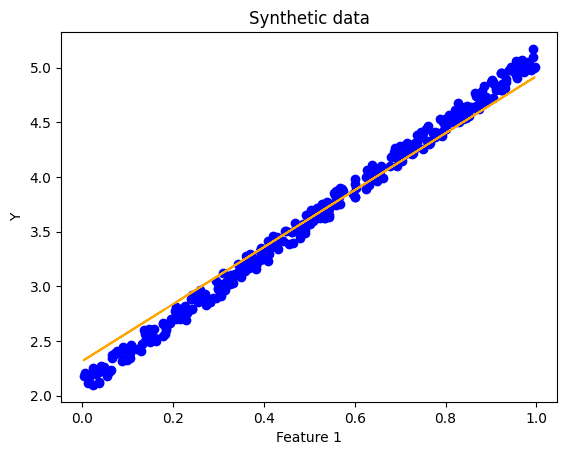

In [31]:
plt.scatter(x_test,y_test,color='blue')
plt.plot(x_test,y_pred,color='orange')
plt.title('Synthetic data')
plt.xlabel('Feature 1')
plt.ylabel('Y')
plt.show()